# Project 9 -- Oscar (Tzu Yang) Huang

**TA Help:** (for instance) John Smith, Alice Jones, etc., list names of any TAs who helped you

- For example: Help with figuring out how to write a function (describe the tasks that they helped you with)

**Collaboration:** N/A, all code is written by me and me only.

**Internet Resources:** Stack Overflow, R documentation, Blogs R project
- https://stackoverflow.com/questions/29135869/r-expand-view-to-see-all-columns: Seeing how to show a certain number of columns in R
- https://www.rdocumentation.org/packages/graphics/versions/3.6.2/topics/plot: Plot function in R
- https://www.rdocumentation.org/packages/base/versions/3.6.2/topics/sort: Sort function in R
- https://www.rdocumentation.org/packages/surveillance/versions/1.23.1/topics/hcl.colors: Learning about hcl.colors function in R
- https://www.rdocumentation.org/packages/graphics/versions/3.6.2/topics/legend: Learning about the legend function in R
- https://blog.r-project.org/2019/04/01/hcl-based-color-palettes-in-grdevices/: Interested in seeing what color palletes are in R
- https://stackoverflow.com/questions/29135869/r-expand-view-to-see-all-columns: Was interested in seeing how to see more rows when calling the head function in R
- https://www.rdocumentation.org/packages/graphics/versions/3.6.2/topics/title: Learning about the title function in R and its parameters
- https://www.rdocumentation.org/packages/graphics/versions/3.6.2/topics/hist: Learning how to make a histogram figure in R
- https://www.rdocumentation.org/packages/graphics/versions/3.6.2/topics/dotchart: Learning about the parameters of dotchart
- https://stackoverflow.com/questions/36229098/using-subset-to-select-ranges-of-data: Learning about how to write the subset in R
- https://www.rdocumentation.org/packages/graphics/versions/3.6.2/topics/boxplot: Learning about how to use boxplot in R
- https://www.rdocumentation.org/packages/grDevices/versions/3.6.2/topics/boxplot.stats: Learning how to get key statistics of a box plot

**ChatGPT, Gemini, Claude, etc:** N/A, all code is written by me and me only.

## Question 1

In [65]:
library(data.table) # Importing the data.table library to use fread function to read csv files more efficiently

myDeathDF <- fread("/anvil/projects/tdm/data/death_records/DeathRecords.csv") # Defining a new dataframe "myDeathDF" by reading the 
# death records csv file using the fread function

dim(myDeathDF) # Getting the dimensions of myDeathDF dataframe so we can see how many columns there are and hence how many we want to 
# display at a time to get a better visualization of the dataset. We get 2631171(rows) and 38(columns)

options(repr.matrix.max.cols= 38) # Setting the max column when displaying head as 38 columns to see what each column means

head(myDeathDF) # Using the head function in R to visualize top 6 results, sorted in chronological order, to see what the dataset looks
# like and examples of some data points that can be used to analyze.

[1] 2631171      38

Id,ResidentStatus,Education1989Revision,Education2003Revision,EducationReportingFlag,MonthOfDeath,Sex,AgeType,Age,AgeSubstitutionFlag,AgeRecode52,AgeRecode27,AgeRecode12,InfantAgeRecode22,PlaceOfDeathAndDecedentsStatus,MaritalStatus,DayOfWeekOfDeath,CurrentDataYear,InjuryAtWork,MannerOfDeath,MethodOfDisposition,Autopsy,ActivityCode,PlaceOfInjury,Icd10Code,CauseRecode358,CauseRecode113,InfantCauseRecode130,CauseRecode39,NumberOfEntityAxisConditions,NumberOfRecordAxisConditions,Race,BridgedRaceFlag,RaceImputationFlag,RaceRecode3,RaceRecode5,HispanicOrigin,HispanicOriginRaceRecode
<int>,<int>,<int>,<int>,<int>,<int>,<chr>,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<chr>,<int>,<int>,<chr>,<int>,<chr>,<chr>,<int>,<int>,<chr>,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<int>
1,1,0,2,1,1,M,1,87,0,43,23,11,0,4,M,4,2014,U,7,C,N,99,99,I64,238,70,0,24,1,1,1,0,0,1,1,100,6
2,1,0,2,1,1,M,1,58,0,37,17,8,0,4,D,3,2014,U,7,C,N,99,99,I250,214,62,0,21,3,3,1,0,0,1,1,100,6
3,1,0,7,1,1,F,1,75,0,41,21,10,0,4,W,2,2014,U,7,C,N,99,99,J449,267,86,0,28,2,2,1,0,0,1,1,100,6
4,1,0,6,1,1,M,1,74,0,40,20,9,0,6,D,1,2014,U,7,C,N,99,99,I48,228,68,0,22,3,3,1,0,0,1,1,100,6
5,1,0,3,1,1,M,1,64,0,38,18,8,0,4,D,2,2014,U,7,C,N,99,99,I250,214,62,0,21,1,1,1,0,0,1,1,100,6
6,1,0,5,1,1,F,1,93,0,44,24,11,0,6,W,4,2014,U,7,C,N,99,99,K137,280,111,0,37,5,5,1,0,0,1,1,100,6


From the above result, we can see that MaritalStatus shows M,D,W,D,D,W which is a bit confusing and doesn't provide much good analysis at the current time. We can also see that DayOfWeekOfDeath shows 4,3,2,1,2,4 and that race shows all 1's which doesn't give us much information to work off of at the moment. The decoder files we examine can help us better understand the Marital Status and Race columns

In [66]:
myDeathRaceDF <- fread("/anvil/projects/tdm/data/death_records/Race.csv") # Reading the race.csv file into myDeathRaceDF dataframe 
# using fread function in R. This is a decoder dataset that can help us understand what the values we saw in the first code block means
# (the 1's we got) for the race column.

dim(myDeathRaceDF) # Getting the dimension of myDeathRaceDF so that we can show all the rows as needed.

head(myDeathRaceDF, n=16) # Showing all the rows in myDeathRaceDF dataframe

[1] 16  2

Code,Description
<int>,<chr>
0,Other races
1,White
2,Black
3,American Indian (includes Aleuts and Eskimos)
4,Chinese
5,Japanese
6,Hawaiian (includes Part-Hawaiian)
7,Filipino
8,Other Asian or Pacific Islander


### Quick analysis on results of showing head of myDeathRaceDF dataframe:
This decoder set helps us understand the death record's race column much more. We can see that 0 represents other races, 1 represents white, 2 represents Black, 3 represents American Indian (includes Aleuts and Eskimos), 4 represents Chinese, 5 represents Japanese, 6 represents Hawaiian (includes Part-Hawaiian), 7 represents Filipino, 8 represents Other Asian or Pacific Islander, 18 represents Asian Indian, 2 represents Korean, 38 represents Samoan , 48 represents Vietnamese, 58 represents Guamanian, 68 represents Other Asian or Pacific Islander in areas reporting codes 18-58, and 78 representing Combined other Asian or Pacific Islander, includes codes 18-68 for areas that do not report them separately. This does provide a lot more details for us to understand the race column and the numbers are much more significant and the 1s seen before represent individuals of the white race.

In [67]:
myDeathMaritalStatusDF <- fread("/anvil/projects/tdm/data/death_records/MaritalStatus.csv") # Reading MaritalStatus csv file into the
# "myDeathMaritalStatusDF" dataframe using the fread function in R

head(myDeathMaritalStatusDF) # Showing all the top 6 rows, sorted by chronological order (it will show all rows since there is only 5),
# of the myDeathMaritalStatusDF dataframe

Code,Description
<chr>,<chr>
S,"Never married, single"
M,Married
W,Widowed
D,Divorced
U,Marital Status unknown


### Quick analysis on results of showing head of myDeathMaritalStatusDF dataframe:
From calling the head of the dataframe, we can see that S represents Never married, single; M represents Married; W represents Widowed; D represents Divorced; U represents Unknown Marital Status. Again, this makes the original death records dataframe much more clear to understand.

In [68]:
myDeathDayOfWeekDF <- fread("/anvil/projects/tdm/data/death_records/DayOfWeekOfDeath.csv")
head(myDeathDayOfWeekDF)

Code,Description
<int>,<chr>
1,Sunday
2,Monday
3,Tuesday
4,Wednesday
5,Thursday
6,Friday


### Quick analysis on results of showing head of myDeathMaritalStatusDF dataframe:
Before this, I had automatically assumed that 1-7 follows the order of Monday to Sunday, but now I realized that just like formatting of dates, time is a very interesting thing that is different based on the geolocation of where a dataset's sample is based off of. We can observe that 1 represents Sunday, 2 represents Monday, 3 represents Tuesday, 4 represents Wednesday, 5 represents Thursday, 6 represents Friday, and 7 represents Saturday. Observing this result made me notice that assumptions in data analysis can be quite dangerous.

In [69]:
myRaceCountDF <- myDeathDF$Race # Creating the dataframe "myRaceCountDF" that only takes the race column of the death records csv.

sort(table(myRaceCountDF), increasing = TRUE) # Displaying the counts of all races in myRaceCount and setting increasing parameter as 
# true so that we get the least common race as the first value shown. 

myRaceCountDF
     58      38       6      78      28      48      18       5      68       7 
    316     623     700    2818    4711    4913    6778    8159    8737   11074 
      4       3       2       1 
  13297   18031  309504 2241510 

### Quick comment on least common entry in myRaceCountDF dataframe & additional comments:
The least common race in myRaceCount is 58 with 316 instances which is Guamanian. It is followed by 38 with 623 instances, which is Samoan and 6 with 700 instances, which is Hawaiian (includes Part-Hawaiian).

Given what we found out about the columns above, I think it will be quite interesting to do further analysis on whether marital status actually affects or leads to death as I think it can be good to pair it with specific types of death such as heart and chronic illnesses, which may benefit more having a partner to take care of you, but I would want to assume that marital status would not as greatly affect accidental deaths besides potential reasons like lifestyle decisions and active attempts for risk adversion. I would also be interested in exploring the day of week column and see if hypotheses like weekends having more accidental deaths relates to more risky actions on weekends or would it be more like a bell curve distribution. I would also be interested in seeing the overall trend of cause of death and locations of injury.

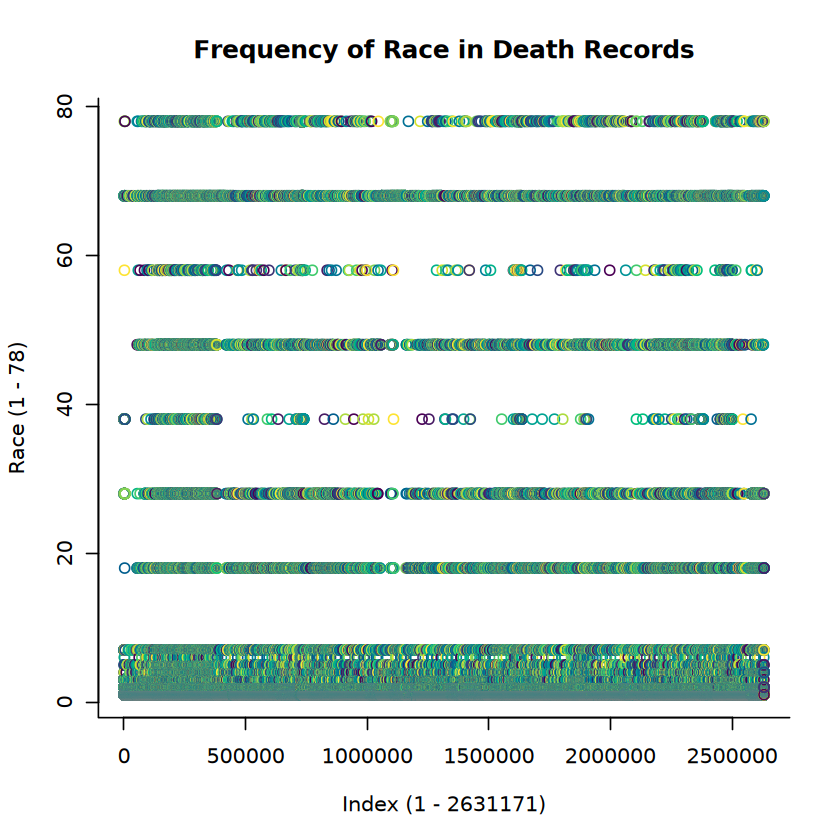

In [70]:
palette(hcl.colors(16, "viridis")) # Setting the color pallete of the plot graph by defining that we need 16 colors and using the viridis
# color pallete. The 16 is quite arbitrary here in my opinion.

plot(myRaceCountDF,
    type = "p",
    xlab = "Index (1 - 2631171)",
    ylab = "Race (1 - 78)",
    bty = "l",
    col = palette()) 
# We call the plot function on the myRaceCountDF dataframe and specify type of the plot as p (corresponding to points on a graph), 
# x-label and y-label are what they correspond to, bty = "l" defines it so that we have only 2 lines of x-axis and y-axis and not an 
# entire container which is redundant, and finally we set color as the color pallete for some distinctions which would be more important
# if we were making histograms for the counts of each race.

title(main = "Frequency of Race in Death Records") # Calling the title specific to the graph to make differentiation of different graphs
# more easy and to easily know the meaning of what each graph is supposed to visualize and represent.

### Quick analysis of myRaceCountDF plot:
There is not extremely much to comment on here, but we can see that there is a huge cluster of values down at around 1-5. We can notice that there is quite little values where the y axis (race) is 58, quite little for 38, and also quite little for 6. The rest are less noticeable in the difference since it is so compressed, but this is quite interesting to notice.

## Question 2

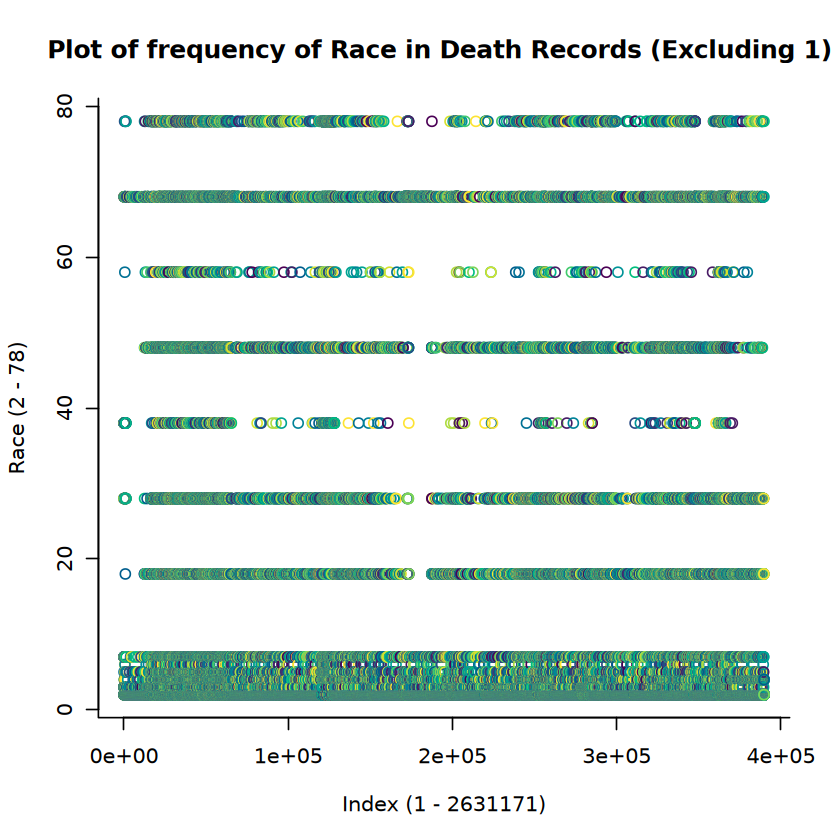

In [71]:
non1DF <- subset(myDeathDF, Race != 1) # Creating a subset called non1DF that takes all rows/instances that don't have the race as white
# or 1, since it has 2241510 instances, making a histogram quite meaningless (I tried using a histogram), since the large value makes
# it hard to notice and visualize the difference between all the other values in the death records dataframe.

plot(non1DF$Race,
    type = "p",
    xlab = "Index (1 - 2631171)",
    ylab = "Race (2 - 78)",
    bty = "l",
    col = palette())
# Since this is essentially the same plot as the one in question 1, besides the fact that the white race is excluded, no comments will
# be made

title(main = "Plot of frequency of Race in Death Records (Excluding 1) ") # Adding a title to make meaning more easy to discern

In [72]:
mean(table(non1DF$Race)) # Mean of the counts of the non1DF sorted by race

median(table(non1DF$Race)) # Median of the counts of the non1DF sorted by race

sd(table(non1DF$Race)) # Standard Deviation of the counts of the non1DF sorted by race

[1] 29973.92

[1] 6778

[1] 84153.49

### Comments on the plot graph after removing race = 1 (white):
There is actually nto a significant different between the previous graph and what we currently have as the race 2 is still quite a lot larger than the least common and even the median. This can be further proven as we can notice that the mean of the dataset is 29973.92 to 2 d.p, but the median frequency of occurence of each race is only 6778, a significant difference versus the mean, showing that the actual trend is significantly skewed by the extremes of race 1,2 and maybe even 3. The analysis here is not the most accurate and clear, but it is a first step to explain why the graph is kind of hard to read. The high standard deviation of 84153.48 suggests that the data is quite spread out and hence visualization is quite hard especially with the upper extremes.

From the graph itself, we can definetly slightly more accurately see that 58 and 38 isn't that clustered (though the difference between the two is hard to observe and I personally thought that at a visual standpoint 58 looks like it had a higher occurence), 6 also can be slightly more easily observed that there aren't a lot of instances and after 78, there is a diminishing difference between the other races with higher values as the scale of increase of frequency ramps up quite quickly.

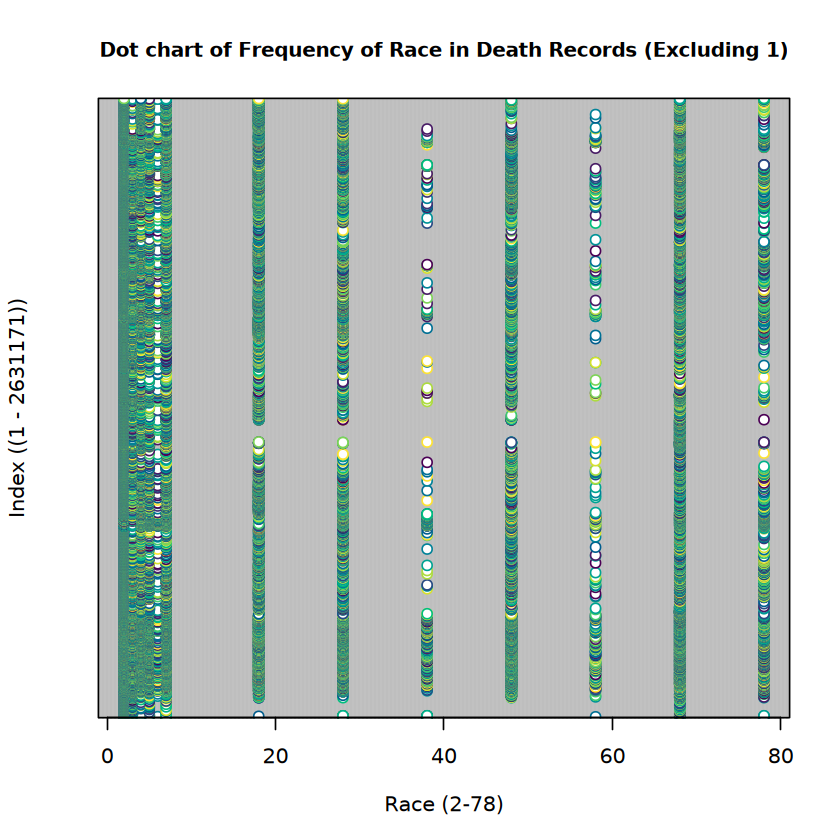

In [73]:
dotchart(non1DF$Race,
        xlab = "Race (2-78)",
        ylab = "Index ((1 - 2631171))",
        col = palette()) # Similar to above, no comment will be made to save time

title(main = "Dot chart of Frequency of Race in Death Records (Excluding 1)",
     cex.main=0.95) 
# Also initializing title to make analysis easier, and setting cex.main = 0.9 means making the title size slightly smaller so it'd fit

### Comments on the dot chart graph after removing race = 1 (white):
I personally didn't notice much difference between using plot and dotchart, but the fact that the x-label is automatically the race from 2-78 made reading the graph much easier and hence allowing us to match the least commonly occuring races in table(non1DF$Race) much easily. It does not actually include the index of the values, which doesn't make a lot of difference since it is very hard to actually read or even infer any meaning by reading the index; however, this lack of y-label may be very detrimental in a histogram context, for example.

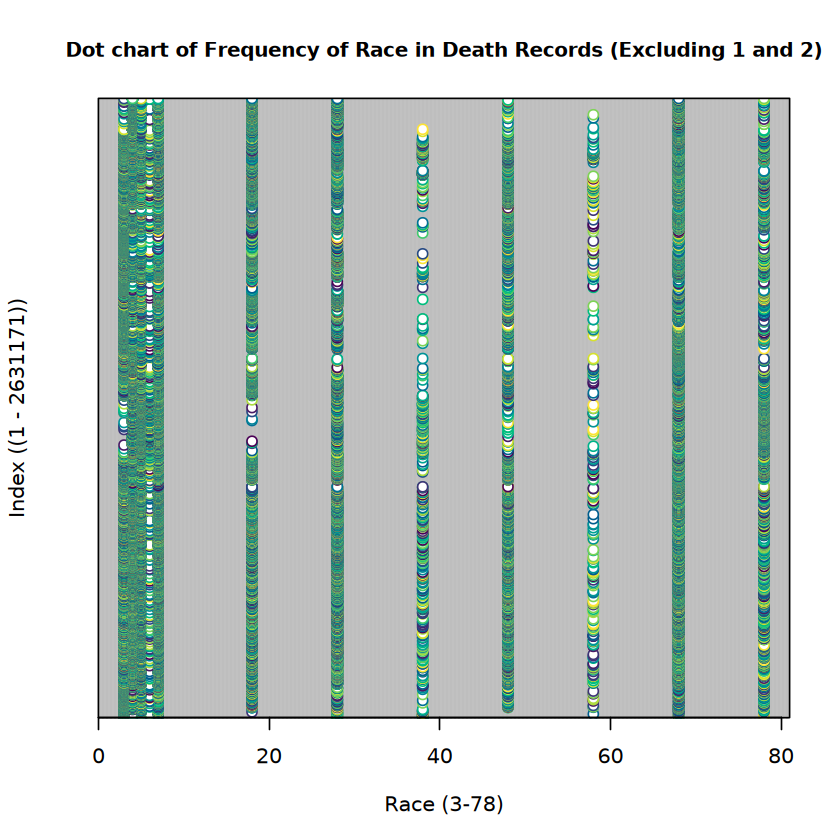

In [74]:
non1and2DF <- subset(myDeathDF, Race != 1 & Race!=2) 

dotchart(non1and2DF$Race,
        xlab = "Race (3-78)",
        ylab = "Index ((1 - 2631171))",
        col = palette()) # Similar to above, no comment will be made to save time

title(main = "Dot chart of Frequency of Race in Death Records (Excluding 1 and 2)",
     cex.main=0.95) 
# Also initializing title to make analysis easier, and setting cex.main = 0.9 means making the title size slightly s smaller so it'd fit

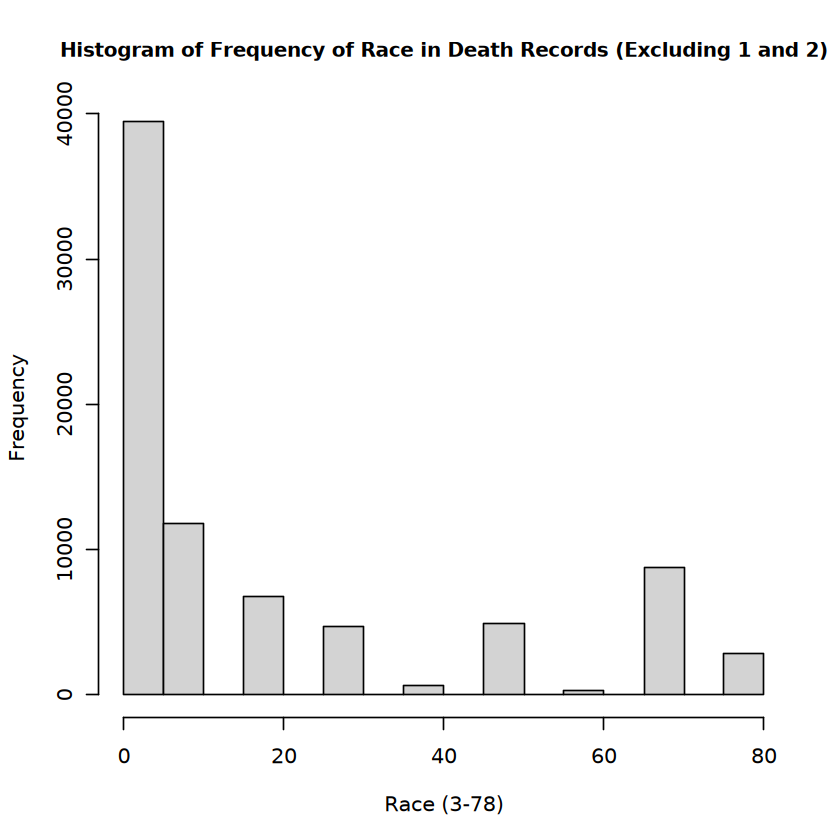

In [75]:
hist(non1and2DF$Race,
    xlab = "Race (3-78)",
    ylab = "Frequency",
    main = title(main = "Histogram of Frequency of Race in Death Records (Excluding 1 and 2)", cex.main=0.95)) 

# Histogram of frequency of each race in death records. It has xlabel and ylabel and the main is the title, which calls the title 
# function automatically, but since we also want to specify the size of the title itself, we pass in cex.main parameter.

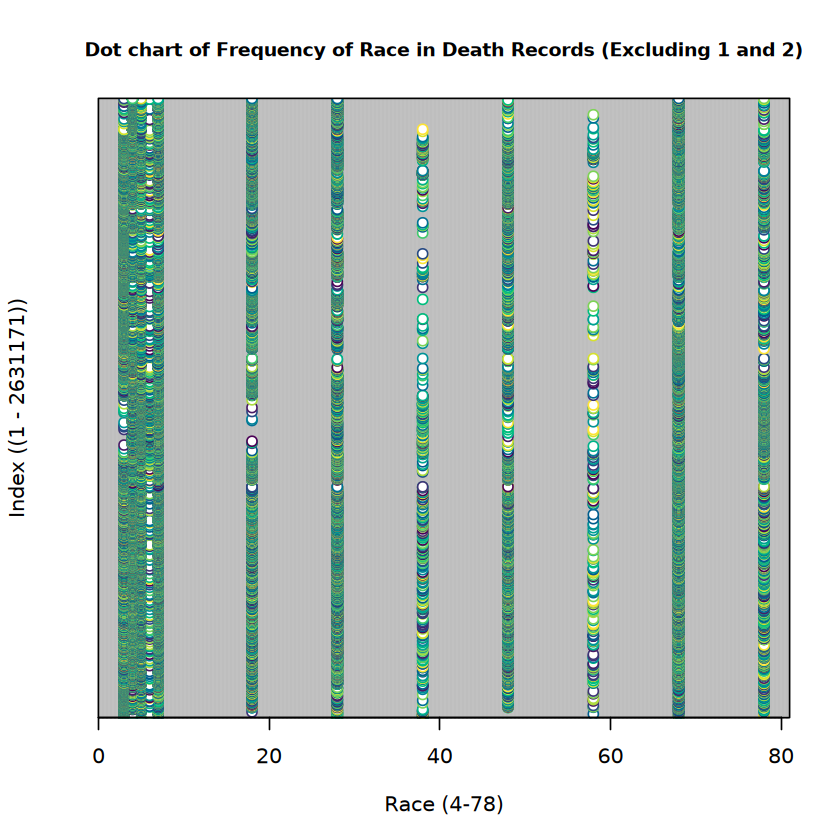

In [76]:
non1and2and3DF <- subset(myDeathDF, Race != 1 & Race!=2 & Race!=3) 

dotchart(non1and2DF$Race,
        xlab = "Race (4-78)",
        ylab = "Index ((1 - 2631171))",
        col = palette()) # Similar to above, no comment will be made to save time

title(main = "Dot chart of Frequency of Race in Death Records (Excluding 1 and 2)",
     cex.main=0.9) 
# Also initializing title to make analysis easier, and setting cex.main = 0.9 means making the title size slightly smaller so it'd fit 

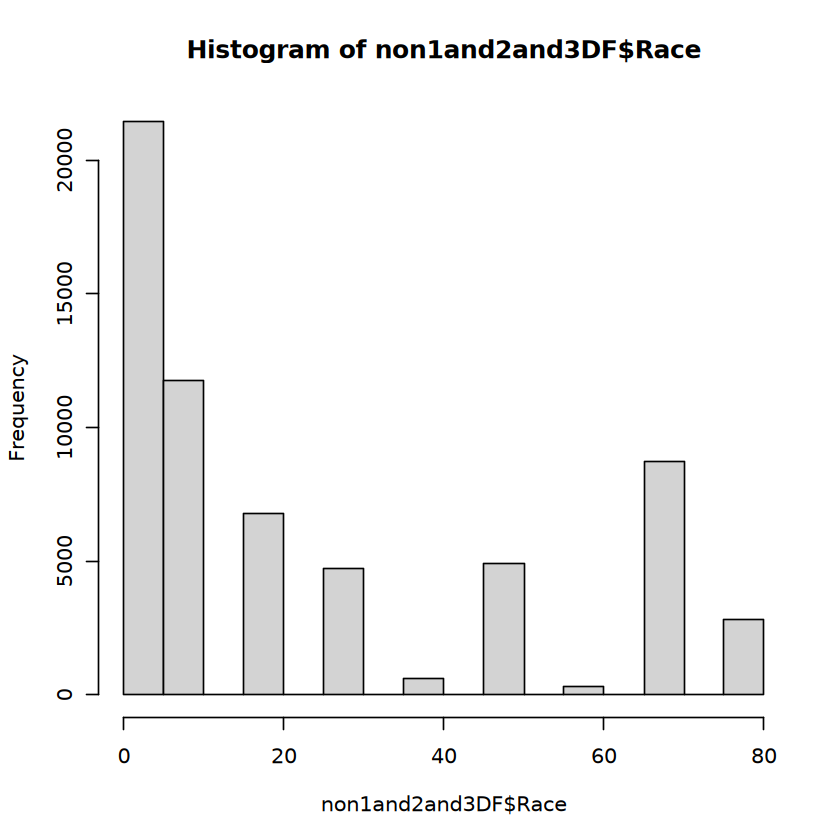

In [77]:
hist(non1and2and3DF$Race)

### Comments on Question 2 questions:
I made the plots unique by labeling both the x and y-axis so that it is more clear what we are observing and analyzing. I also changed the color of the graph by changing it so that it is more easy to observe. I also changed the plots to have x and y-axis and not be contained in a box as that's unnecessary. I also added a title to the plots as it makes it easier to differentiate between different plots. I didn't do any further customization as I felt like the current settings make it quite easy to observe the trends, and that further changes should be made on using a different type of chart rather than adjusting the seetings of the plots themselves. As mentioned above, I added titles, a clear color pallete, x and y-axis labels that allow for the data to be more readable, further enhancements would be slightly redundant and quite unnecessary. I tested removing 1, both 1 and 2, and 1,2, and 3. I noticed that the graph with all 3 excluded is the most clear as you can clearly see the discrepancies between the race of a lower number than compared to 38, for example. I do think that finding an actual statisticla model or test to determine would be more ideal moving forwards but this is a cool start and I am interested in seeing more trends.

## Question 3

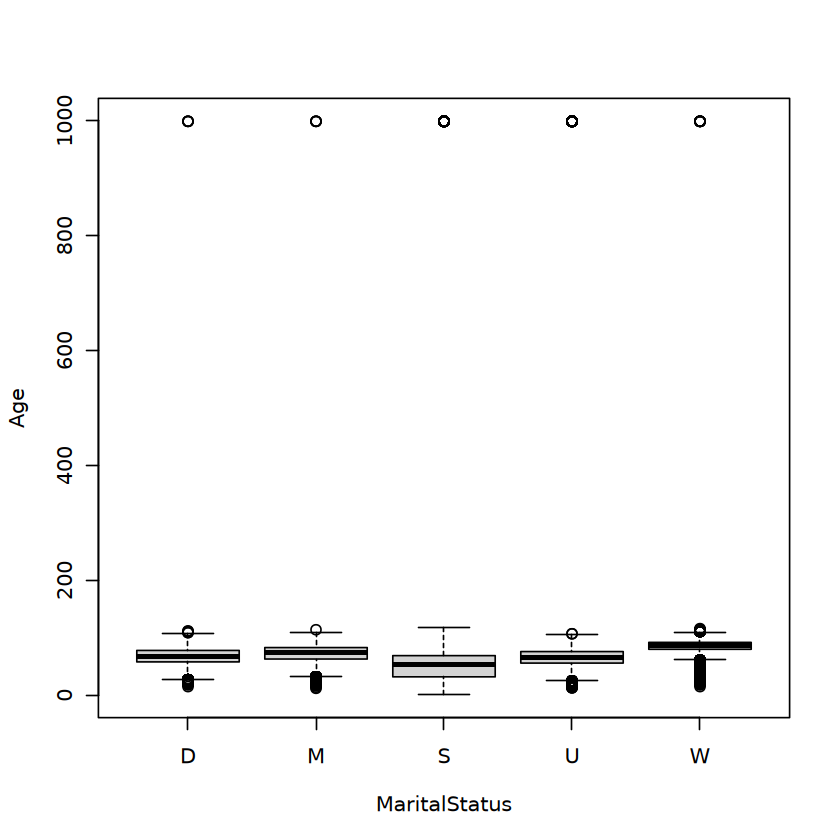

In [78]:
boxplot(Age ~ MaritalStatus, data = myDeathDF) # Making a box plot of the myDeathDF dataframe by finding the trend between age of death
# and the person's marital status. Right now, as noted by the tutorial, it is very unclear as the values at 999 (erorrs) not only are 
# invalid and should be excluded, but it also makes the values really hard to read and for us to discern any meaning

28,33,1,28,62
58,63,32,56,80
68,74,54,65,87
78,83,69,75,92
108,109,118,103,110


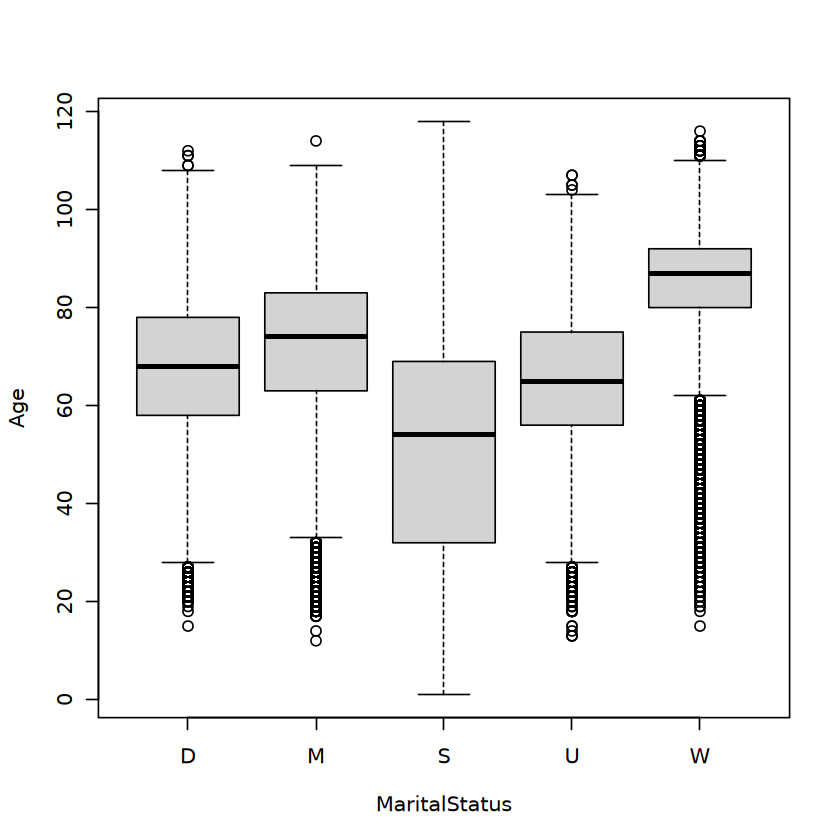

In [79]:
non999DF <- subset(myDeathDF, Age!=999) # Creaing a new subset where we exclude 

non999bp <- boxplot(Age ~ MaritalStatus, data = non999DF) # Creating a variable that creates a boxplot with Age as the y-axis and
# marital status as the x-axis (the categorical variable), and we pass in the dataframe we just made in the previous step

non999bp$stats # We output the key statistics of each categorical variable in the dataframe for further analysis.

### Some comments and analaysis of the boxplot after removing values where age is 999 (an error code):
By removing the age at 999, it makes the graph much more readable and we can much better analyze these values. First thing to note is that the median age of death is 68 for divorcees, 74 for married, 54 for single, 65 for unknown and 87 for widowed. The difference in between each categorical variable is not significantly different, and we should refrain from concluding any causal relationships between being of a specific marital status and consequently dying earlier or later. We can notice that there are no outliers for single people within the dataset, which is really interesting since widowed samples have a lot of outliers and the rest of the categories have some amount of outliers. We can also notice that the interquartile range for single people is quite high, meaning that the variance for when people who have died that are single can be quite varied. 

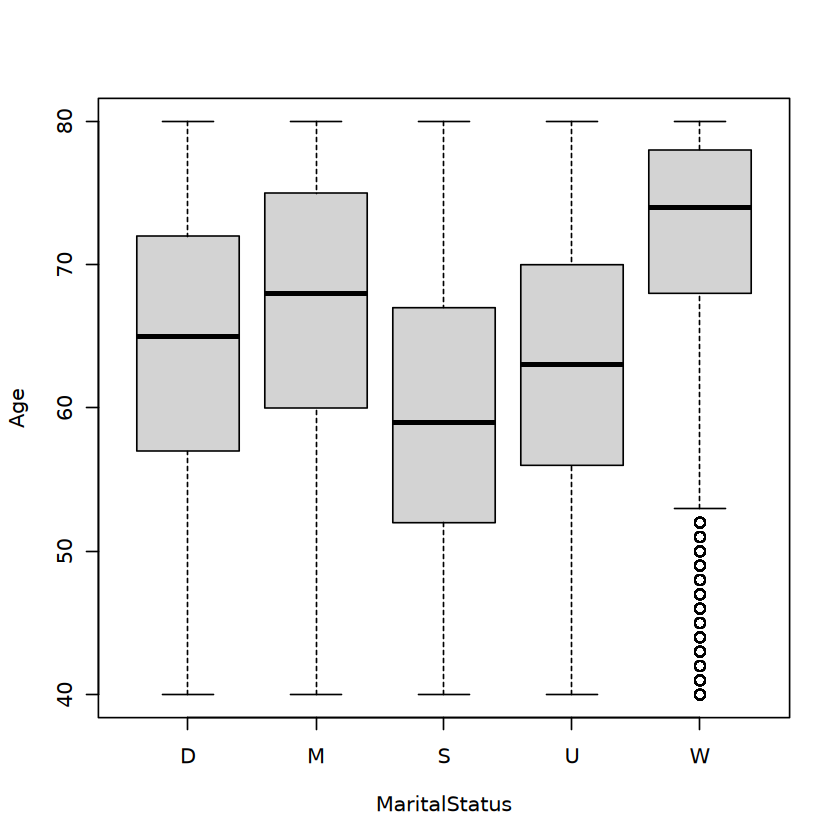

In [80]:
non999RangedDF <- subset(myDeathDF, Age <= 80 & Age >= 40) # Creaing a new subset where we only take those with age ranging 40-80

non999Rangebp <- boxplot(Age ~ MaritalStatus, data = non999RangedDF) # Creating a box plot of non999RangedDF dataframe

### Some comments and analaysis of the boxplot after restricting age range to 40-80:
By only taking a specific range of the age, we greatly increase the interquartile range of all the marital statuses. I would assume that this is likely due to the outliers being removed from being considered and that the upper and lower quartiles are not as wrongly represented by these said outliers. However, notice that for widowed people, the outliers still exists quite a considerable amount, even though the IQR has increased, likely due to the fact that the Q2 and Q3 are quite closely distributed, but the rest lay in the extremes in both end.

## Question 4

33,62
63,80
74,87
83,92
109,110


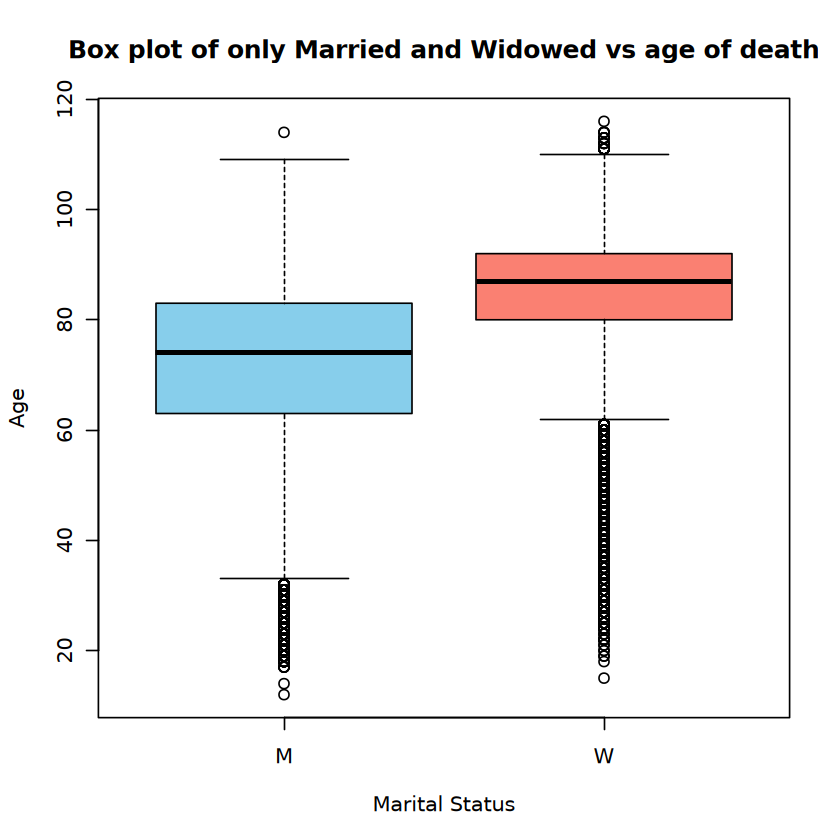

In [81]:
onlyMWDF <- subset(myDeathDF, Age != 999 & MaritalStatus %in% c("M","W")) # Creaing a new subset where we only
# take those with age ranging 40-80

onlyMWDF <- boxplot(Age ~ MaritalStatus, data = onlyMWDF, 
            main = "Box plot of only Married and Widowed vs age of death",
            xlab = "Marital Status",
            ylab = "Age",
            col = c("skyblue", "salmon")) 
# Creating a box plot of onlyMWDF with appropiate title, x-label, y-label and color for the two marital status to easily differentiate
# visually between the two and consequentely identify key trends.

onlyMWDF$stats

### My explanation for the widowed vs married death data:
The most obvious difference between the two marital status is that married has a median age of death of 74 while widowed has a median age of death of 87, a ~17% difference between the two. Maried and Widowed have Q1s of 63 and 80 respectively, and Q3 of 83 and 92 respectively; from this, we can notice that Married individuals varied quite a bit in terms of their age of death, with an IQR of 20 years while widowed only had an IQR of 12 years which could reveal that widowed had a more consistent and tight distibution within that range. However, when we zoom out we can notice that widowed have a lot of outliers on both ends (values above 110 and values below 62) while married had not as much outliers below 33 and only 1 outlier above 109. This does suggest that the widowed group has a tight distribution around the median but very inconsistent beyond that. One posisble explanation could be that the psychological damage of being a widow is very devastating and that regardless of age, it may lead to suicide or other deaths related to the grief of the loss. The lesson did explain that although the age at which most people die varies regardless of their marital status, but the relatively high number of upper extreme outliers that are widowed explains a reverse causal relationship where older people tend to be widowed; this still doesn't explain the lower extremes despite the afore-mentioned explanation. It is still confusing and interesting so further analysis and literature search can be performed to notice and explain the trend.


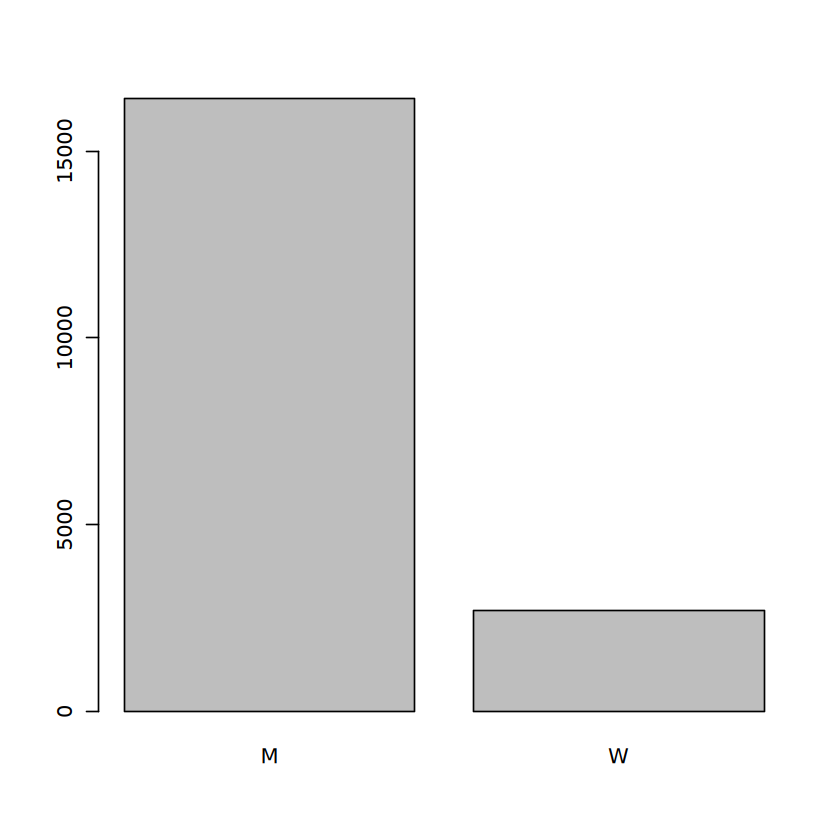

In [82]:
onlyMW60DF <- subset(myDeathDF, MaritalStatus %in% c("M","W") & Age == 60) # Creaing a subset of only married and widows who died at age 60
bp <- barplot(table(onlyMW60DF$MaritalStatus)) # Creating a barplot by getting the counts of the two marital statuses

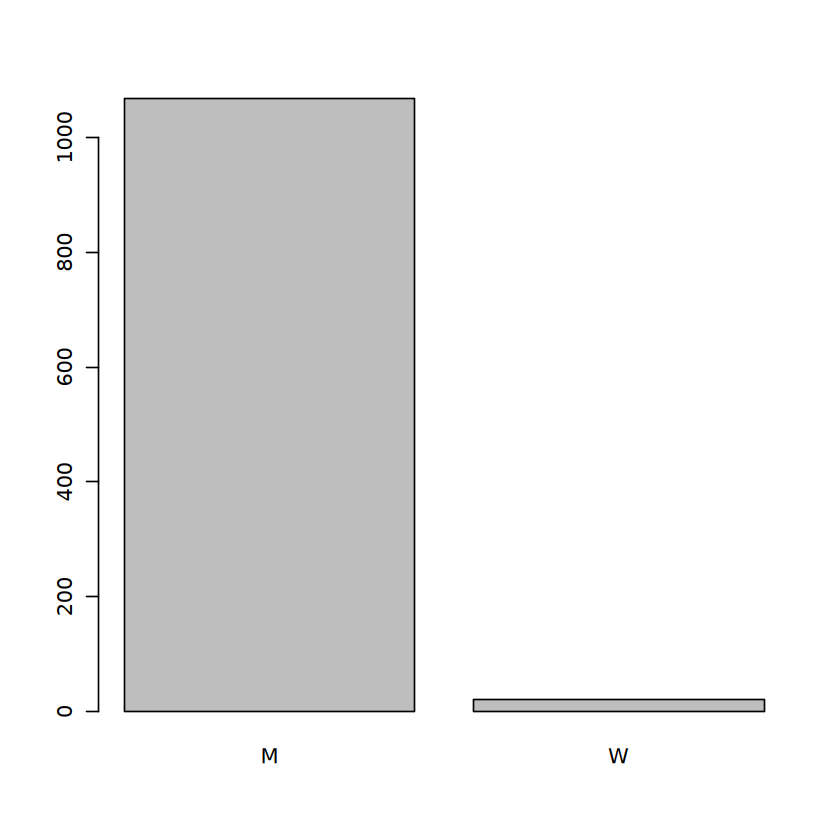

In [83]:
onlyMW30DF <- subset(myDeathDF, MaritalStatus %in% c("M","W") & Age == 30) # Creaing a subset of only married and widows who died at age 30
bp <- barplot(table(onlyMW30DF$MaritalStatus)) # Creating a barplot by getting the counts of the two marital statuses

### My explanation for the widowed vs married death data for ages 60 and ages 30:
The number of deaths at 60 for married way surppased the number of widow deaths of around 17k versus 2.6k. The same held true for ages at 30 with married having around 1.1k occurences while widowed only had around 10 instances or so (could not really tell from the graph). I think this kind of explains what we noticed before of the married dataset following quite close to what would seem to be a nornmal distribution curve while the widowed one had many outliers, which could just be a lack of a bigger sample size for widowed deaths. I also think this does make sense on an intuitive level as I would assume there is a much higher chance for someone to be married than to be a widow. 

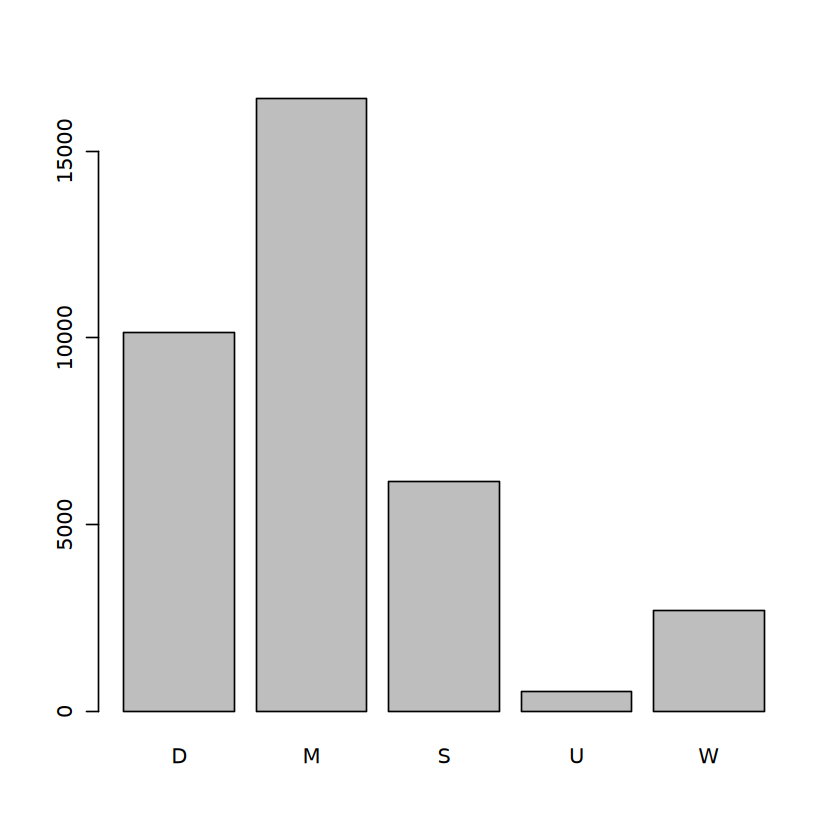

In [84]:
only60DF <- subset(myDeathDF, Age == 60) # Creating a subset of death where ages are at 60
bp <- barplot(table(only60DF$MaritalStatus)) # Creating a barplot by getting the counts of the marital statuses

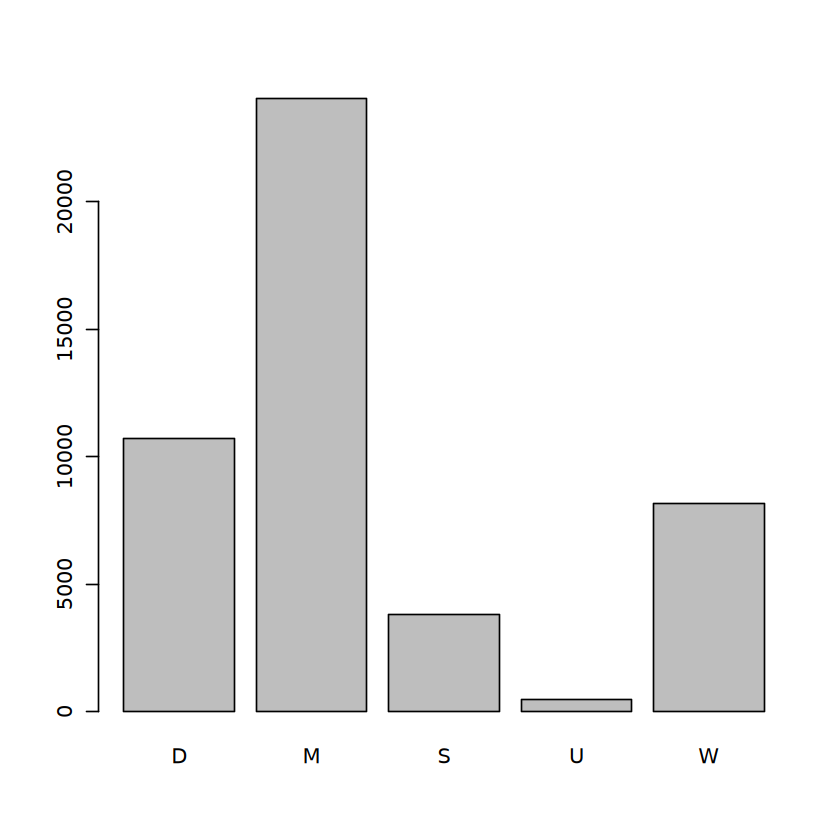

In [85]:
only70DF <- subset(myDeathDF, Age == 70) #  Creating a subset of death where ages are at 70
bp <- barplot(table(only70DF$MaritalStatus)) # Creating a barplot by getting the counts of the marital statuses

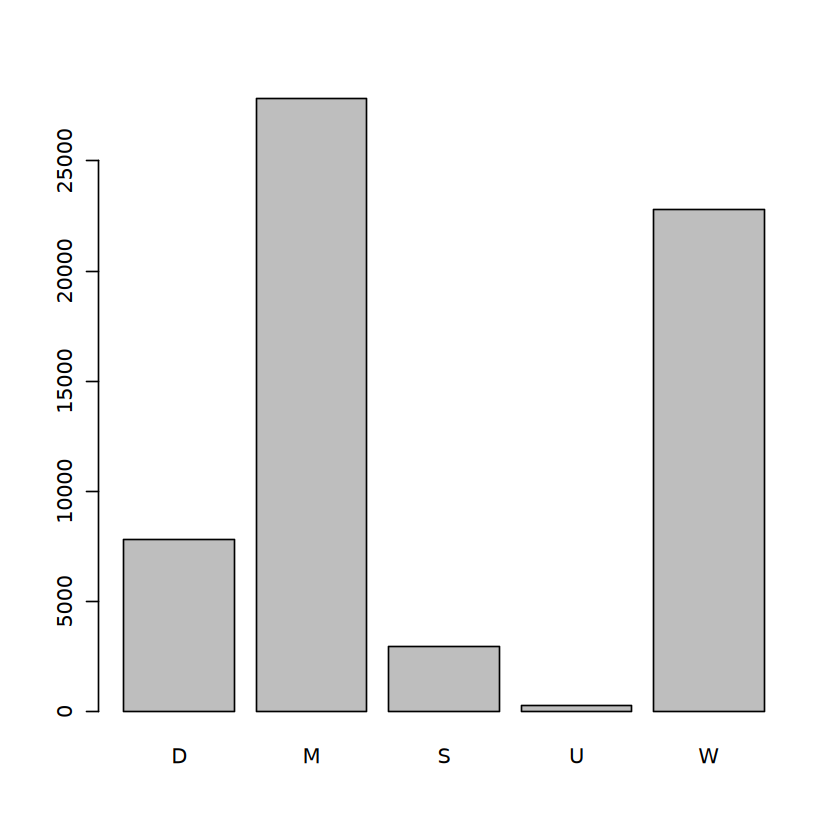

In [86]:
only80DF <- subset(myDeathDF, Age == 80) #  Creating a subset of death where ages are at 80
bp <- barplot(table(only80DF$MaritalStatus)) # Creating a barplot by getting the counts of the marital statuses

### My explanation for the counts of each marital status at ages 60, 70, and 80:
For instances where age is 60, we notice that married is the highest at around 18k, divorced following at around 10k and single right aftera at around 6k. The drop is quite substantial afterwards with widows at around 2500 and unknown at around 1k. This kind of connects with wwhat we observed before of how widowed shyed in comparison with married instances. This does make quite a lot of sense since a lot of people are married at this age and I would assume divorced right after makes a lot of sense as well. As for where age is 50, the distribution is similar except divorced is more similar to widowed and single is less than widowed. As for 80, we notice that widowed skyrockets and is slightly comparable to married.

## Pledge

By submitting this work I hereby pledge that this is my own, personal work. I've acknowledged in the designated place at the top of this file all sources that I used to complete said work, including but not limited to: online resources, books, and electronic communications. I've noted all collaboration with fellow students and/or TA's. I did not copy or plagiarize another's work.

> As a Boilermaker pursuing academic excellence, I pledge to be honest and true in all that I do. Accountable together – We are Purdue.

https://www.purdue.edu/odos/osrr/honor-pledge/
